In [48]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [17]:
def show(img, title=""):
    fig, ax = plt.subplots(figsize=(12, 3))
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    plt.show()

(428, 718)
100


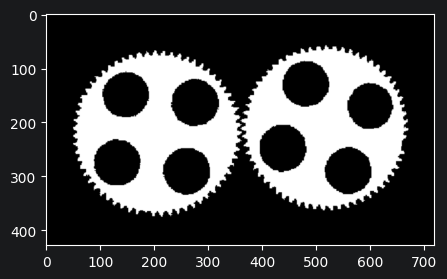

In [18]:
image = cv2.imread("image.png", cv2.IMREAD_COLOR_RGB)
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

print(gray.shape)
print(len(np.unique(gray)))

show(gray)

[  0 255]
2


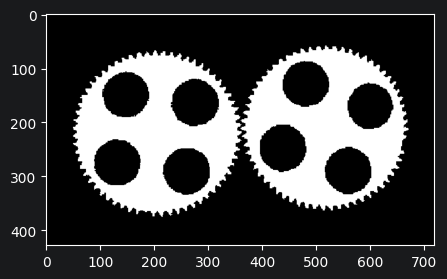

In [19]:
_, B = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)
print(np.unique(B))
print(len(np.unique(B)))

show(B)


In [20]:
def disk(d):
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (d, d))

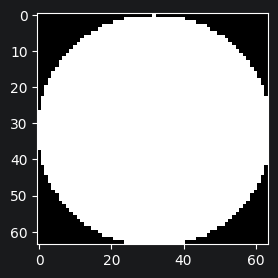

In [25]:
show(disk(64))

In [26]:
def make_ring(ksize, width):
    assert width % 2 == 0
    el = disk(ksize)
    inner_el = disk(ksize - width)
    inner_el = cv2.copyMakeBorder(inner_el, *(width // 2,) * 4, borderType=cv2.BORDER_CONSTANT, value=0)
    return el - inner_el

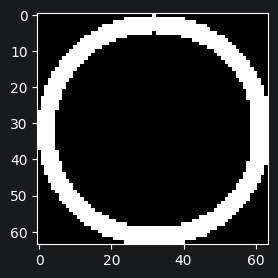

In [30]:
show(make_ring(64, 10))

In [31]:
n, labels, stats, centroids = cv2.connectedComponentsWithStats(255 - B)
print(n)
print(stats)

10
[[    50     58    621    318  94065]
 [     0      0    718    428 167031]
 [   438     87     86     85   5689]
 [   104    106     87     85   5649]
 [   231    120     89     88   5952]
 [   558    127     85     86   5554]
 [   396    205     86     88   5911]
 [    89    232     86     85   5761]
 [   516    246     86     88   5814]
 [   216    249     87     86   5878]]


In [32]:
n, labels, stats, centroids = cv2.connectedComponentsWithStats(B)
print(n)
print(stats)

3
[[     0      0    718    428 213239]
 [   360     58    311    306  46542]
 [    50     67    312    309  47523]]


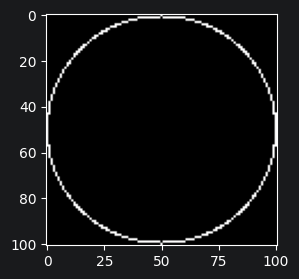

8


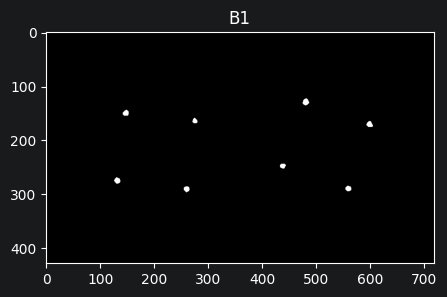

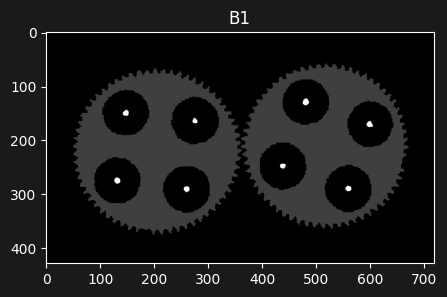

In [36]:
ring = make_ring(101, 2)

show(ring)

B1 = cv2.erode(B, ring)
n, _ = cv2.connectedComponents(B1)
print(n - 1)
show(B1, "B1")
show(cv2.add(B // 4, B1), "B1")

2


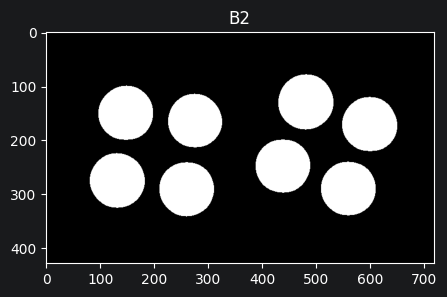

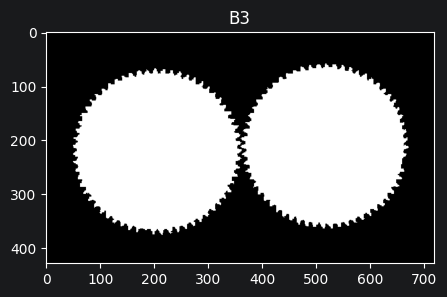

In [35]:
B2 = cv2.dilate(B1, disk(91))
B3 = cv2.bitwise_or(B, B2)

n, _ = cv2.connectedComponents(255 - B3)
print(n)

show(B2, "B2")
show(B3, "B3")

In [37]:
for d in [251, 261, 271, 281, 285, 289]:
    print(d, cv2.erode(B3, disk(d)).max())

251 255
261 255
271 255
281 255
285 255
289 0


2


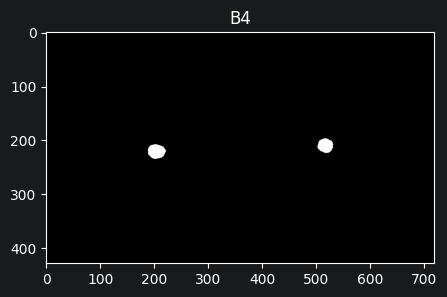

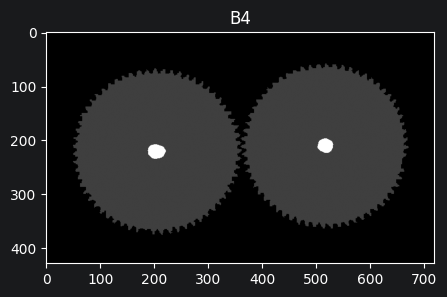

In [40]:
B4 = cv2.erode(B3, disk(261))
n, _ = cv2.connectedComponents(B4)
print(n - 1)

show(B4, "B4")
show(cv2.add(B3 // 4, B4), "B4")

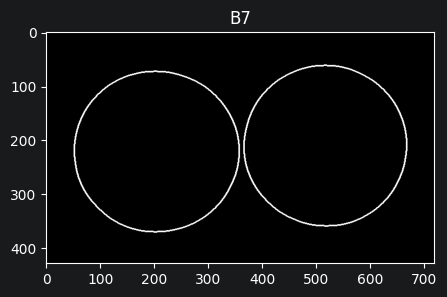

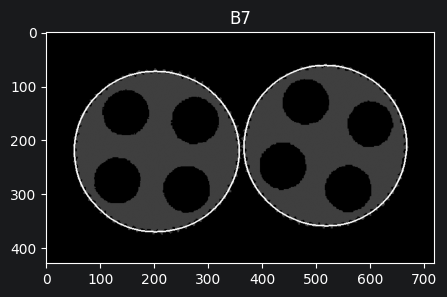

In [45]:
B5 = cv2.dilate(B4, disk(269))
B6 = cv2.dilate(B5, disk(7))

B7 = cv2.subtract(B6, B5)
show(B7, "B7")
show(cv2.add(B // 4, B7), "B7")

124


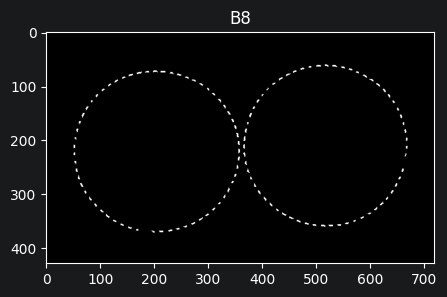

In [46]:
B8 = cv2.bitwise_and(B, B7)
n, _ = cv2.connectedComponents(B8)
print(n - 1)
show(B8, "B8")

In [49]:
rows = []
for d in range(9, 31, 2):
    B9 = cv2.dilate(B8, disk(d))
    D = cv2.subtract(B7, B9)
    n, _ = cv2.connectedComponents(D)
    rows.append({"tip_spacing": d, "defects": n - 1})

pd.DataFrame(rows).set_index("tip_spacing")

,defects
tip_spacing,
9,81
11,13
13,2
15,2
17,2
19,2
21,2
23,2
25,0


In [51]:
rows = []
for s in range(259, 277, 2):
    B5 = cv2.dilate(B4, disk(s))
    B6 = cv2.dilate(B5, disk(7))
    B7 = cv2.subtract(B6, B5)
    B8 = cv2.bitwise_and(B, B7)
    B9 = cv2.dilate(B8, disk(17))
    D = cv2.subtract(B7, B9)
    n, _ = cv2.connectedComponents(D)
    rows.append({"spacer": s, "defects": n - 1})

pd.DataFrame(rows).set_index("spacer")

,defects
spacer,
259,0
261,0
263,1
265,1
267,2
269,2
271,2
273,2
275,4


2


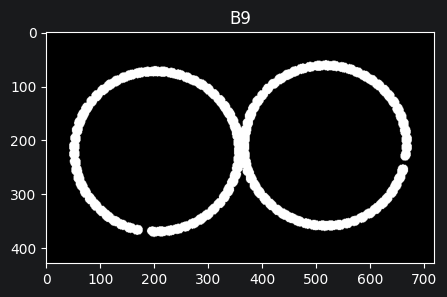

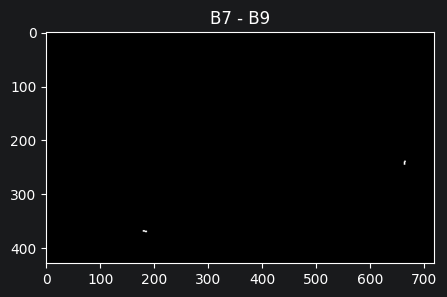

In [52]:
B5 = cv2.dilate(B4, disk(269))
B6 = cv2.dilate(B5, disk(7))
B7 = cv2.subtract(B6, B5)
B8 = cv2.bitwise_and(B, B7)
B9 = cv2.dilate(B8, disk(17))
D = cv2.subtract(B7, B9)

n, _ = cv2.connectedComponents(D)
print(n - 1)

show(B9, "B9")
show(D, "B7 - B9")

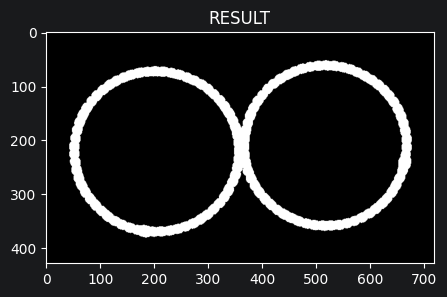

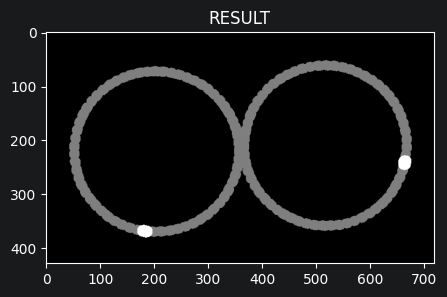

In [53]:
D2 = cv2.dilate(D, disk(21))
RESULT = cv2.bitwise_or(D2, B9)

show(RESULT, "RESULT")
show(cv2.add(B9 // 2, D2), "RESULT")

2
664 242
183 369


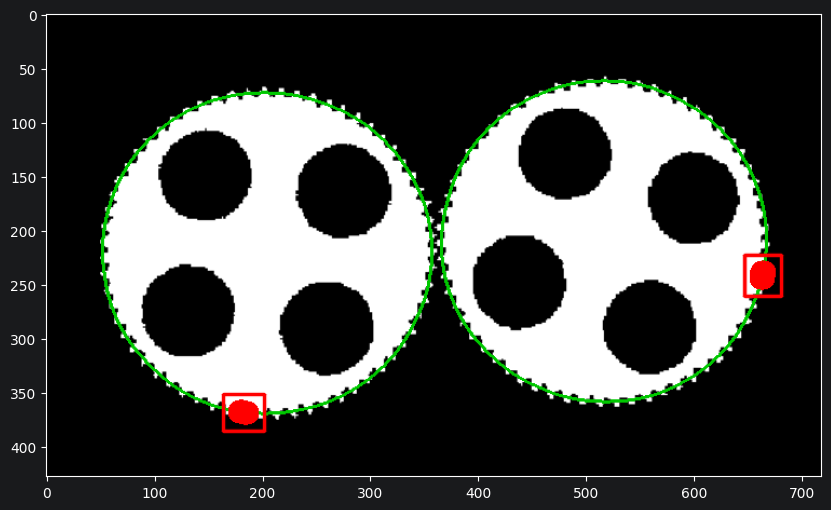

In [55]:
count, masks = cv2.connectedComponents(D2)
print(count - 1)

vis = image.copy()
vis[B7 > 0] = (0, 200, 0)
vis[D2 > 0] = (255, 0, 0)

for mask_label in range(1, count):
    target_mask = masks == mask_label
    x1, y1, w, h = cv2.boundingRect(target_mask.astype(np.uint8) * 255)
    x2 = x1 + w
    y2 = y1 + h
    print(x1 + w // 2, y1 + h // 2)
    vis = cv2.rectangle(vis, (x1 - 5, y1 - 5), (x2 + 5, y2 + 5), (255, 0, 0), 2, cv2.LINE_AA)

fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(vis)
plt.show()

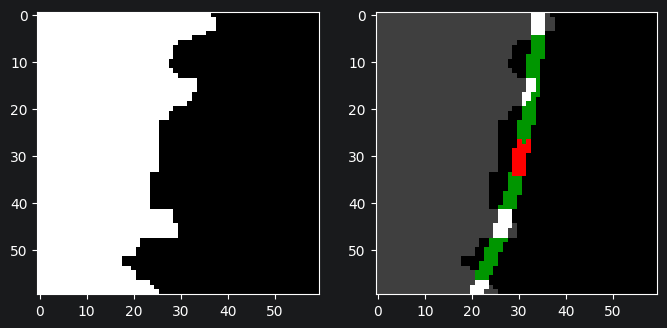

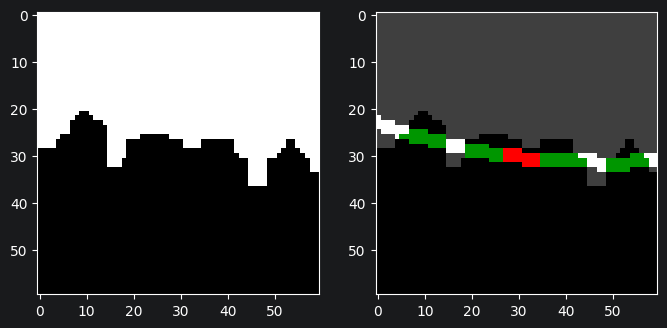

In [56]:
vis2 = np.dstack([B // 4] * 3)
vis2[B7 > 0] = (0, 150, 0)
vis2[B8 > 0] = (255, 255, 255)
vis2[D > 0] = (255, 0, 0)

for mask_label in range(1, count):
    ys, xs = np.where(masks == mask_label)
    x, y = int(xs.mean()), int(ys.mean())

    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(B[y-30:y+30, x-30:x+30], cmap="gray")
    axes[1].imshow(vis2[y-30:y+30, x-30:x+30])
    plt.show()